# EDA – Univariate analysis by year

How much energy do SERL households use, when in the day and year, how unequal is use between households, and how does it vary with dwelling and household characteristics? 2020–2023, whole sample unless stated.

**Inputs:** the daily-statistics file (yearly and monthly rows) and the four half-hourly files, read with `serl_utils`.
**Outputs:** figures inline; `outputs/repro/covariate_gradients_2023.csv`.


Every number below comes from **one group of households in one unit**: SERL rows stack overlapping groups (whole sample, heating fuel, PV, region, EPC, …) and three units per quantity, and `serl_utils` refuses to mix them. The earlier version of this notebook averaged across all rows, e.g. reporting an "energy mean" of 206 that combined gas in Wh with electricity per m², and reading the resulting skewness as "extreme demand events".


In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import serl_utils as su

warnings.filterwarnings("ignore", category=UserWarning)
yearly = su.load_yearly()
monthly = su.load_monthly(su.CLEAN_CSV)
hh = su.load_half_hourly()
QUANTITIES = ["Electricity imports", "Electricity exports", "Electricity net", "Gas", "Gas + electricity imports"]
MAIN = ["Electricity imports", "Gas"]
YEARS = list(su.YEARS)
Path("outputs/repro").mkdir(parents=True, exist_ok=True)
print(f"yearly rows {len(yearly):,}, monthly rows {len(monthly):,}, half-hourly rows {len(hh):,}")

yearly rows 40,860, monthly rows 490,320, half-hourly rows 1,961,280


## 1. Use per household by year

Mean daily use of the whole sample, with 95% confidence intervals from SERL's standard errors (the uncertainty of the mean, not the spread between households).


Mean kWh/day per household, whole sample
year                        2020   2021   2022   2023  change 2020→2023 %
Electricity imports        10.94  10.11   8.78   8.51              -22.14
Electricity exports         0.18   0.29   0.02   0.01              -92.85
Electricity net            10.76   9.82   8.75   8.50              -21.00
Gas                        36.85  38.67  30.44  29.06              -21.14
Gas + electricity imports  44.32  44.59  36.29  34.77              -21.55


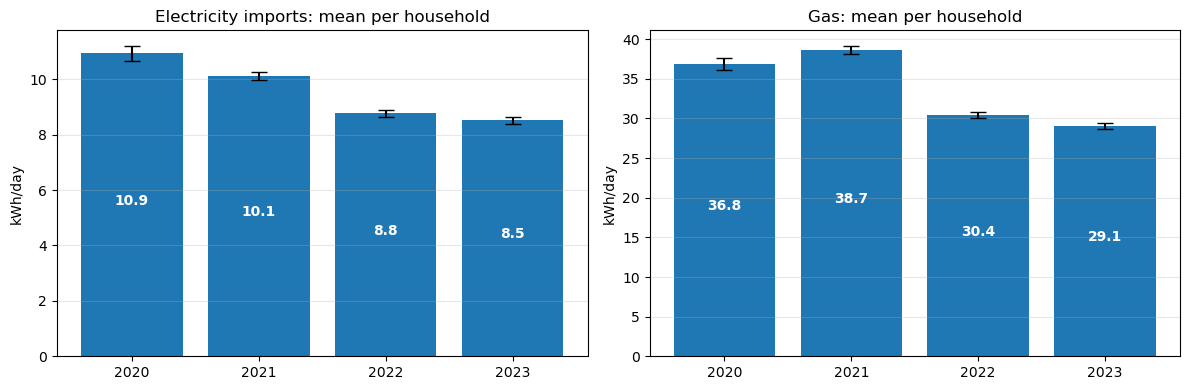

In [2]:
rows = []
for q in QUANTITIES:
    s = su.select_slice(yearly, q, "kWh/day").set_index("year")
    rows.append(s["mean"].rename(q))
levels = pd.DataFrame(rows)
levels["change 2020→2023 %"] = 100 * (levels[2023] / levels[2020] - 1)
print("Mean kWh/day per household, whole sample")
print(levels.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, q in zip(axes, MAIN):
    s = su.select_slice(yearly, q, "kWh/day").set_index("year")
    ax.bar(s.index.astype(str), s["mean"], yerr=1.96 * s["standard_error_mean"], capsize=6)
    for x, v in zip(s.index.astype(str), s["mean"]):
        ax.text(x, v * 0.5, f"{v:.1f}", ha="center", color="white", fontweight="bold")
    ax.set_title(f"{q}: mean per household"); ax.set_ylabel("kWh/day"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 2. Daily profile by year

Average use in each half-hour of the day (SERL's annual mean half-hourly profile), converted from Wh to kWh per half-hour.


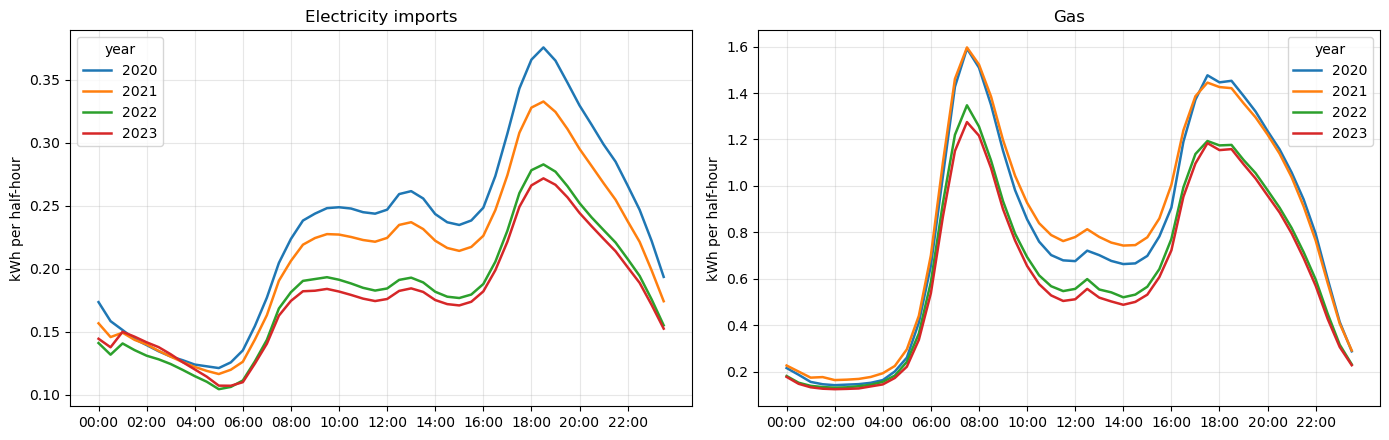

           quantity  year  kWh/day peak time  peak kWh/half-hour  peak / average  16:00–19:00 share %
Electricity imports  2020   11.025     18:30               0.376           1.635               17.360
Electricity imports  2021   10.083     18:30               0.333           1.584               17.013
Electricity imports  2022    8.682     18:30               0.283           1.564               16.641
Electricity imports  2023    8.499     18:30               0.272           1.535               16.350
                Gas  2020   37.656     07:30               1.591           2.028               20.829
                Gas  2021   39.116     07:30               1.597           1.959               20.253
                Gas  2022   30.831     07:30               1.347           2.097               20.911
                Gas  2023   29.498     07:30               1.275           2.075               21.252


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
rows = []
for ax, q in zip(axes, MAIN):
    for y in YEARS:
        p = su.daily_profile(hh, y, q, "Wh", to_kwh=True)
        ax.plot(range(48), p.to_numpy(), label=str(y), linewidth=1.8)
        rows.append({"quantity": q, "year": y, "kWh/day": p.sum(), "peak time": p.idxmax(),
                     "peak kWh/half-hour": p.max(), "peak / average": p.max() / p.mean(),
                     "16:00–19:00 share %": 100 * p.loc["16:00":"18:30"].sum() / p.sum()})
    ax.set_xticks(range(0, 48, 4), [f"{h:02d}:00" for h in range(0, 24, 2)])
    ax.set_title(q); ax.set_ylabel("kWh per half-hour"); ax.legend(title="year"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(pd.DataFrame(rows).round(3).to_string(index=False))

## 3. How unequal is use between households?

SERL reports, for each group, the mean, median and quartiles *across households*. A mean above the median, and a positive quartile (Bowley) skewness, mean that a minority of high users pulls the average up. This is the meaningful version of the earlier skewness/kurtosis figures, which were computed across the pooled table rather than across households.


Spread between households, 2023 (kWh/day)
                 quantity  households  mean  median    Q1    Q3    sd  mean/median  Bowley skew
      Electricity imports        8830  8.51    6.99  4.74 10.33  5.99         1.22         0.20
      Electricity exports        8480  0.01    0.00  0.00  0.00  0.26          NaN          NaN
          Electricity net        8830  8.50    6.99  4.73 10.31  6.00         1.22         0.19
                      Gas        7500 29.06   25.99 17.29 37.01 17.80         1.12         0.12
Gas + electricity imports        5540 34.77   31.62 20.72 44.48 20.56         1.10         0.08


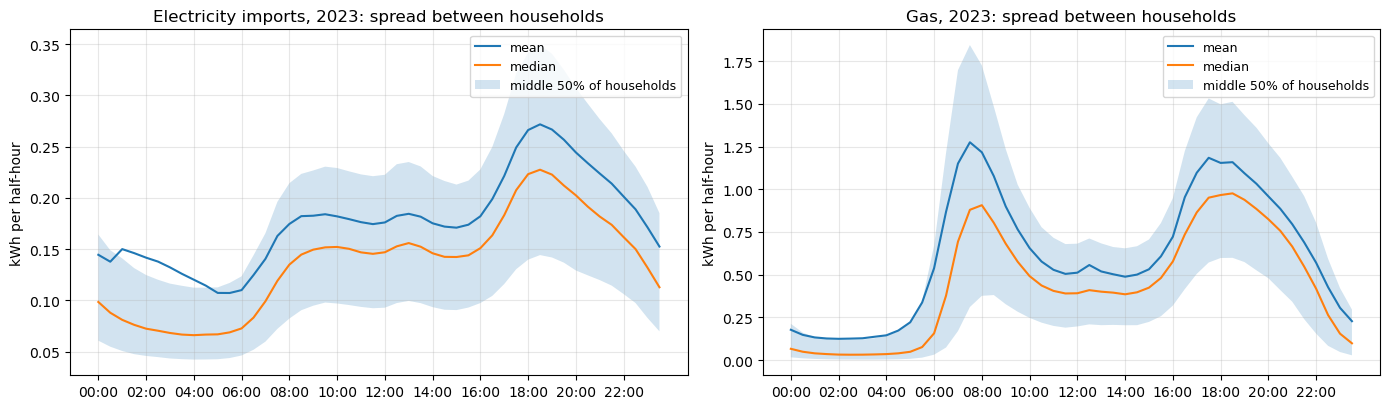

In [4]:
rows = []
for q in QUANTITIES:
    r = su.select_slice(yearly[yearly["year"].eq(2023)], q, "kWh/day").iloc[0]
    q1, med, q3 = r["25th_percentile"], r["median"], r["75th_percentile"]
    rows.append({"quantity": q, "households": r["n_rounded"], "mean": r["mean"], "median": med, "Q1": q1, "Q3": q3,
                 "sd": r["standard_deviation"], "mean/median": r["mean"] / med if med else np.nan,
                 "Bowley skew": (q3 + q1 - 2 * med) / (q3 - q1) if q3 > q1 else np.nan})
print("Spread between households, 2023 (kWh/day)")
print(pd.DataFrame(rows).round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharex=True)
for ax, q in zip(axes, MAIN):
    s = su.select_slice(hh[hh["year"].eq(2023)], q, "Wh")
    ax.plot(range(48), s["mean"] / 1000, label="mean")
    ax.plot(range(48), s["median"] / 1000, label="median")
    ax.fill_between(range(48), s["25th_percentile"] / 1000, s["75th_percentile"] / 1000, alpha=0.2, label="middle 50% of households")
    ax.set_xticks(range(0, 48, 4), [f"{h:02d}:00" for h in range(0, 24, 2)])
    ax.set_title(f"{q}, 2023: spread between households"); ax.set_ylabel("kWh per half-hour")
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Seasonal pattern

Mean daily use in each calendar month (monthly rows of the daily file), whole sample.


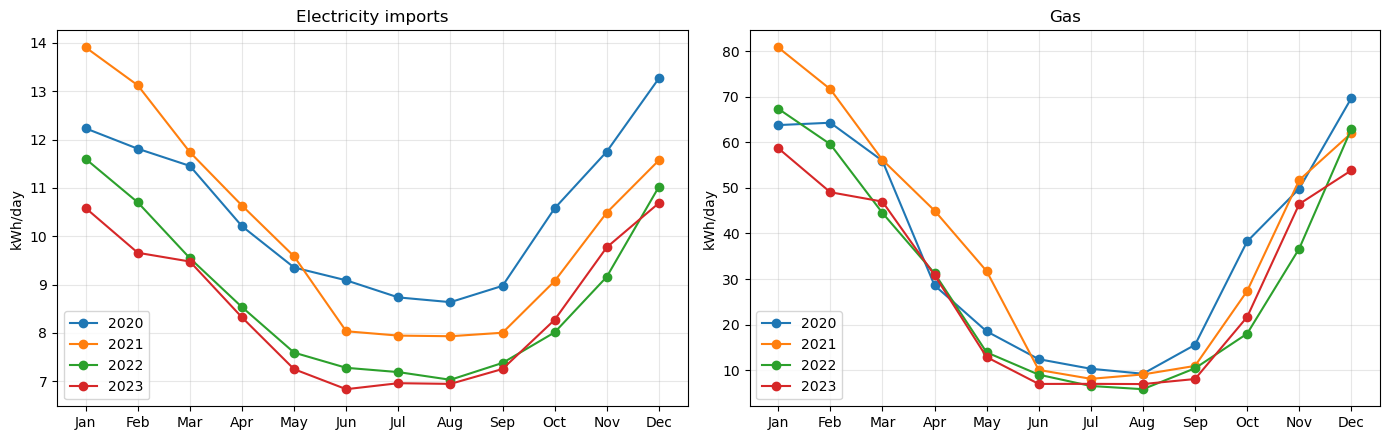

           quantity  year  winter (Dec–Feb)  summer (Jun–Aug)  winter/summer
Electricity imports  2020             12.44              8.82           1.41
Electricity imports  2021             12.87              7.97           1.61
Electricity imports  2022             11.11              7.16           1.55
Electricity imports  2023             10.31              6.91           1.49
                Gas  2020             65.95             10.63           6.20
                Gas  2021             71.53              9.05           7.90
                Gas  2022             63.32              7.11           8.91
                Gas  2023             53.89              6.96           7.75


In [5]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
rows = []
for ax, q in zip(axes, MAIN):
    s = su.monthly_series(monthly, q, "kWh/day")
    for y in YEARS:
        part = s.loc[str(y)]
        ax.plot(range(12), part.to_numpy(), marker="o", label=str(y))
        rows.append({"quantity": q, "year": y,
                     "winter (Dec–Feb)": part[part.index.month.isin([12, 1, 2])].mean(),
                     "summer (Jun–Aug)": part[part.index.month.isin([6, 7, 8])].mean()})
    ax.set_xticks(range(12), MONTHS); ax.set_title(q); ax.set_ylabel("kWh/day"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
season = pd.DataFrame(rows)
season["winter/summer"] = season["winter (Dec–Feb)"] / season["summer (Jun–Aug)"]
print(season.round(2).to_string(index=False))

## 5. Differences by dwelling and household (2023)

Mean daily use for each level of eight SERL characteristics (all other households in that level, whole year 2023). Each chart compares disjoint groups, so the bars can be compared directly.


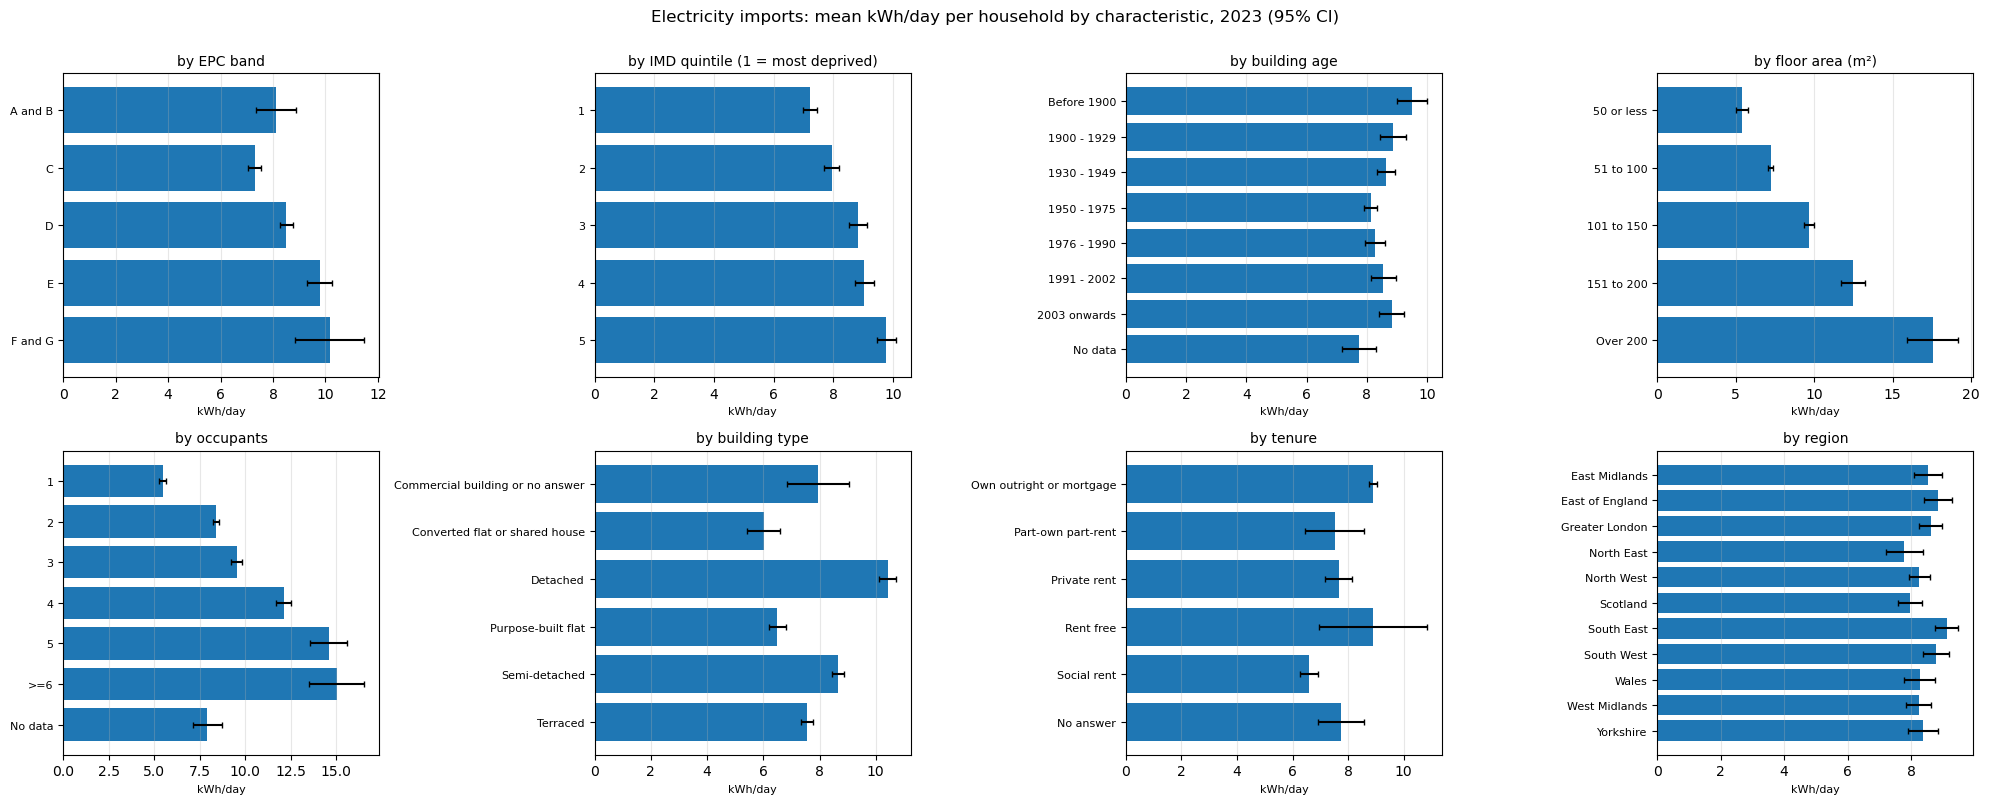

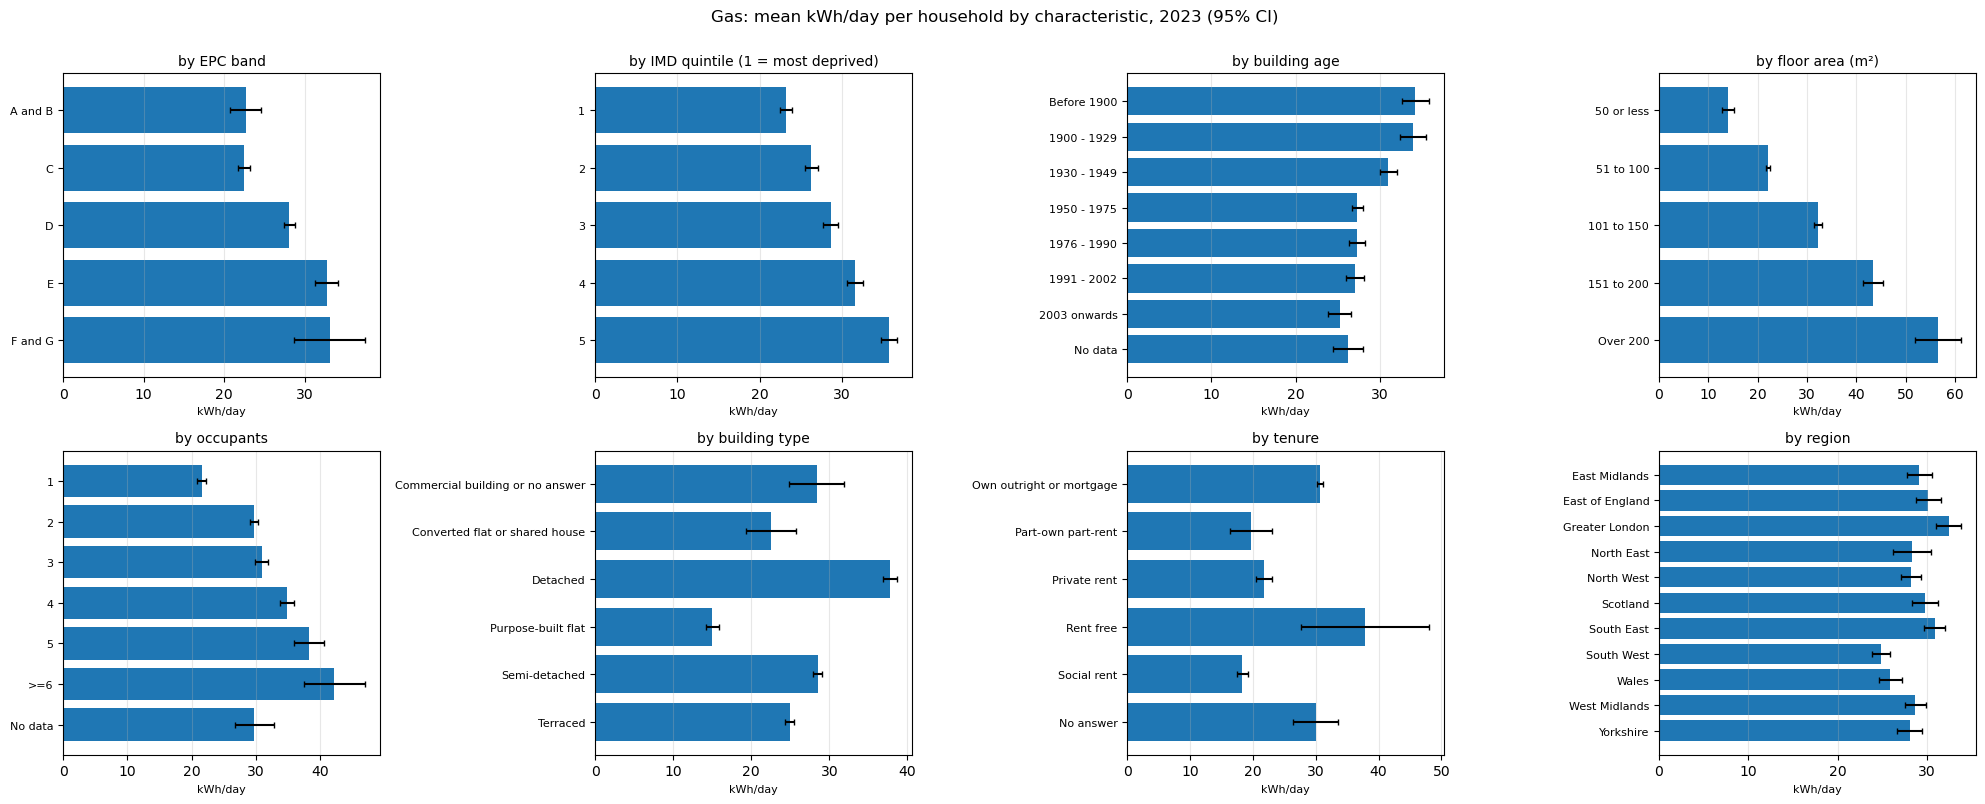

Ratio of highest to lowest level (2023)
quantity             Electricity imports   Gas
characteristic                                
IMD_quintile                        1.35  1.54
building_age                        1.23  1.36
building_type                       1.73  2.52
currentEnergyRating                 1.39  1.47
floor_area_m2                       3.26  4.03
num_occupants                       2.75  1.96
region                              1.17  1.30
tenure                              1.35  2.06
Saved outputs/repro/covariate_gradients_2023.csv


In [6]:
SEGMENTS = {"currentEnergyRating": "EPC band", "IMD_quintile": "IMD quintile (1 = most deprived)",
            "building_age": "building age", "floor_area_m2": "floor area (m²)", "num_occupants": "occupants",
            "building_type": "building type", "tenure": "tenure", "region": "region"}
# natural order for ordered characteristics; others alphabetical, with "No data"/"No answer" last
ORDER = {"floor_area_m2": ["50 or less", "51 to 100", "101 to 150", "151 to 200", "Over 200"],
         "building_age": ["Before 1900", "1900 - 1929", "1930 - 1949", "1950 - 1975", "1976 - 1990", "1991 - 2002", "2003 onwards"]}
def ordered(seg, levels):
    first = [lv for lv in ORDER.get(seg, []) if lv in levels]
    rest = sorted((lv for lv in levels if lv not in first), key=lambda v: (v in ("No data", "No answer"), v))
    return first + rest

y23 = yearly[yearly["year"].eq(2023)]
rows = []
for q in MAIN:
    fig, axes = plt.subplots(2, 4, figsize=(20, 8))
    for ax, (seg, label) in zip(axes.flat, SEGMENTS.items()):
        s = su.select_slice(y23, q, "kWh/day", segment=seg)
        s = s[~s["segment_3_value"].astype(str).isin(["All", "nan"])]
        s = s.set_index(s["segment_3_value"].astype(str))
        s = s.loc[ordered(seg, list(s.index))]
        ax.barh(s.index, s["mean"], xerr=1.96 * s["standard_error_mean"], capsize=2)
        ax.invert_yaxis(); ax.tick_params(axis="y", labelsize=8)
        ax.set_title(f"by {label}", fontsize=10); ax.set_xlabel("kWh/day", fontsize=8); ax.grid(axis="x", alpha=0.3)
        for lv, r in s.iterrows():
            rows.append({"quantity": q, "characteristic": seg, "level": lv, "kWh/day": r["mean"],
                         "se": r["standard_error_mean"], "households": r["n_rounded"]})
    fig.suptitle(f"{q}: mean kWh/day per household by characteristic, 2023 (95% CI)", y=1.0)
    plt.tight_layout(); plt.show()
gradients = pd.DataFrame(rows)
spread = gradients.groupby(["quantity", "characteristic"])["kWh/day"].agg(lambda v: v.max() / v.min())
print("Ratio of highest to lowest level (2023)")
print(spread.unstack(0).round(2).to_string())
gradients.to_csv("outputs/repro/covariate_gradients_2023.csv", index=False)
print("Saved outputs/repro/covariate_gradients_2023.csv")

## 6. Weather by year

Mean outdoor temperature and heating degree days experienced by SERL households (whole sample).


In [7]:
w = su.select_slice(yearly, "Gas", "kWh/day").set_index("year")[["mean_temp", "mean_hdd", "mean_solar"]]
w.columns = ["mean temperature °C", "heating degree days per day", "solar irradiance"]
print(w.round(2).to_string())

      mean temperature °C  heating degree days per day  solar irradiance
year                                                                    
2020                11.02                         5.17            125.87
2021                10.41                         5.71            121.29
2022                11.31                         5.05            126.20
2023                11.19                         5.06            121.72
